# Stock code and description consistency

Exploratory checks only. Product codes are categorical identifiers; shared prefixes or casing do not prove identical products. No forecasting model is trained here.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'pyproject.toml').exists() else Path.cwd().parent
folder=ROOT/'reports/generated'
family=pd.read_csv(folder/'candidate-family-audit.csv',dtype={'candidate_code_base':str})
case=pd.read_csv(folder/'code-case-variants.csv',dtype={'normalized':str,'stock_code':str})
family_stats=json.loads((folder/'candidate-family-audit.json').read_text())
case_stats=json.loads((folder/'code-case-audit.json').read_text())
print('Candidate family audit:',family_stats)
print('Case audit:',case_stats)

Candidate family audit: {'groups': 399, 'products': 1311, 'case_collision_groups': 82, 'zero_token_overlap_groups': 4, 'no_comparable_tokens_groups': 0, 'warning': 'Token overlap is only a review heuristic; codes and descriptions do not prove common product identity.'}
Case audit: {'normalized_groups': 170, 'distinct_original_codes': 340, 'groups_with_same_day_sales_for_multiple_variants': 119, 'groups_with_descriptions_at_cutoff': 170, 'groups_with_multiple_descriptions_at_cutoff': 4, 'note': 'Same-day sales or matching descriptions do not prove identical products; no codes were merged. Date ranges use the full dataset and are descriptive only.'}


## Candidate family sizes and word overlap
A shared numeric base is a hypothesis. The token-overlap heuristic ignores selected colors and common words; low overlap can identify examples to inspect, but neither high nor low overlap proves identity.

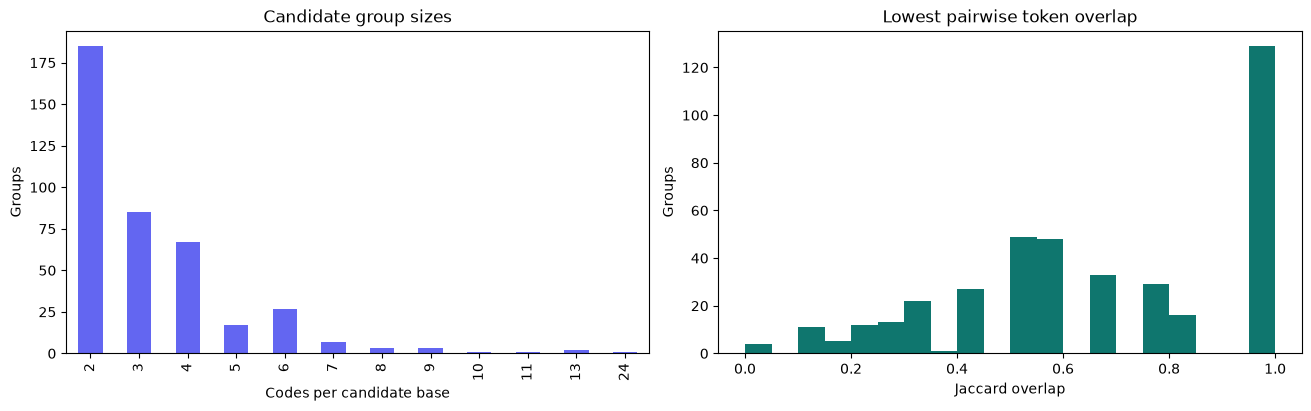

,candidate_code_base,n_products,min_token_similarity,case_only_collision,codes,descriptions
72,40018,2,0.000000,False,40018E | 40018F,TEA TIME PAPER LANTERNS | CHERRY DESIGN PAPERL...
267,85023,3,0.000000,False,85023A | 85023B | 85023C,CRYSTAL LARGE JEWELLED PHOTO FRAME | EAU DE NI...
160,84247,8,0.000000,False,84247C | 84247E | 84247G | 84247H | 84247J | 8...,PACK/12 BLUE REINDEER CARD | PACK/12 XMAS FUN ...
153,84029,5,0.000000,True,84029C | 84029D | 84029E | 84029G | 84029c,BROWN FURRY HOT WATER BOTTLE | LEOPARD PRINT H...
108,71101,2,0.111111,False,71101A | 71101E,ANGEL ON KNEES METAL POLE 100CM H | STANDING F...
301,85170,4,0.125000,False,85170A | 85170B | 85170C | 85170D,SET/6 IVORY BIRD T-LIGHT CANDLES | SET/6 BLACK...
85,47503,7,0.125000,False,47503A | 47503E | 47503F | 47503G | 47503H | 4...,ASS FLORAL PRINT MULTI SCREWDRIVER | ASS FLORA...
317,90000,4,0.125000,False,90000A | 90000B | 90000C | 90000D,RASPBERRY ANT COPPER FLOWER NECKLAC | MIDNIGHT...
128,72800,6,0.125000,False,72800A | 72800B | 72800C | 72800D | 72800E | 7...,S/4 BLACK DINNER CANDLE SILVER FLOC | 4 PURPLE...
189,84596,13,0.125000,True,84596B | 84596E | 84596F | 84596G | 84596I | 8...,SMALL DOLLY MIX DESIGN ORANGE BOWL | SMALL LIC...


In [2]:
fig,ax=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
family.n_products.value_counts().sort_index().plot.bar(ax=ax[0],color='#6366f1');ax[0].set(title='Candidate group sizes',xlabel='Codes per candidate base',ylabel='Groups')
family.min_token_similarity.plot.hist(bins=20,ax=ax[1],color='#0f766e');ax[1].set(title='Lowest pairwise token overlap',xlabel='Jaccard overlap',ylabel='Groups')
plt.show()
display(family.sort_values('min_token_similarity').head(15))

## Case-only variants
The following audit uses full-history sales dates, so it is descriptive and cannot define a historical training cohort. Matching descriptions and same-day sales do not establish that codes can be merged.

In [3]:
display(case.head(30))
display(family[family.case_only_collision].head(15))

,normalized,stock_code,first_sale,last_sale,transaction_days,units
0,15056BL,15056BL,2009-12-01,2011-12-09,427,9646.0
1,15056BL,15056bl,2009-12-01,2011-12-09,62,126.0
2,15056N,15056N,2009-12-01,2011-12-09,475,11370.0
3,15056N,15056n,2010-06-08,2011-11-30,67,180.0
4,15056P,15056P,2009-12-01,2011-12-08,254,2529.0
5,15056P,15056p,2010-06-24,2011-12-05,33,50.0
6,15060B,15060B,2009-12-03,2011-11-18,291,1438.0
7,15060B,15060b,2010-03-05,2011-11-20,5,5.0
8,18096C,18096C,2009-12-01,2010-02-24,17,123.0
9,18096C,18096c,2009-12-01,2010-01-25,3,8.0


,candidate_code_base,n_products,min_token_similarity,case_only_collision,codes,descriptions
3,15056,6,0.666667,True,15056BL | 15056N | 15056P | 15056bl | 15056n |...,EDWARDIAN PARASOL BLACK | EDWARDIAN PARASOL NA...
5,15060,2,1.000000,True,15060B | 15060b,FAIRY CAKE DESIGN UMBRELLA | FAIRY CAKE DESIGN...
28,18096,2,1.000000,True,18096C | 18096c,WHITE ROUND PORCELAIN TLIGHT HOLDER | WHITE RO...
30,18098,4,0.600000,True,18098A | 18098B | 18098C | 18098c,PINK PORCELAIN B'FLY OIL BURNER | BLUE PORCELA...
32,35004,8,0.500000,True,35004B | 35004C | 35004G | 35004P | 35004S | 3...,SET OF 3 BLACK FLYING DUCKS | SET OF 3 COLOURE...
45,35809,3,0.750000,True,35809A | 35809B | 35809a,ENAMEL PINK TEA CONTAINER | ENAMEL BLUE RIM TE...
67,37482,4,0.400000,True,37482B | 37482P | 37482b | 37482p,CUBIC MUG BLUE POLKA DOT | CUBIC MUG PINK POLK...
71,37494,2,1.000000,True,37494A | 37494a,FAIRY CAKE CERAMIC BUTTER DISH | FAIRY CAKE CE...
87,47518,2,1.000000,True,47518F | 47518f,ICON PLACEMAT POP ART ELVIS | ICON PLACEMAT PO...
88,47556,2,1.000000,True,47556B | 47556b,TEA TIME TEA TOWELS | TEA TIME TEA TOWELS


## Interpretation
- Many code bases have several similarly named variants, but heuristic groups can contain non-identical items.
- Codes with uppercase and lowercase suffixes can split recorded histories. They are kept separate until transaction-level evidence and a documented policy support a merge.
- Descriptions are noisy and missing in some cutoff snapshots. Text features are optional candidates; validate their value later using training-only vocabularies and held-out periods.
- Product quality, manufacturing origin and verified categories are not provided.